In [11]:
from pgmpy.models import BayesianNetwork
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from pgmpy.estimators import BayesianEstimator
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# 1. Sobre os Dados<br>
&ensp;&ensp;Os dados com que estamos trabalhando referem-se aos resultados de cada país e de cada indivíduo participante da Olimpíada Internacional de Matemática (IMO) ao longo dos anos de 1959 - 2024, obtidos no seguinte endereço endereço do Kaggle: https://www.kaggle.com/datasets/joebeachcapital/international-mathematical-olympiad-imo-data. Note que tais dados foram obtidos antes de uma recente reformulação no site da competição https://www.imo-official.org/results/, que mudou a maneira como as informações são exibidas. Por isso, realizamos um scraping no site atualizado, guardando os resultados em dois novos arquivos "imo_teams.csv" e "imo_individual.csv". Assim, mais à frente, realizaremos uma combinação dos dados do kaggle e do scraping a fim de enriquecer nossos dados com o melhor que cada versão tem a oferecer.<br>
&ensp;&ensp;Cada linha da tabela abaixo traz informações sobre a participação de um país em uma edição específica da competição. Cada coluna representa um possível dado nesse contexto, sendo eles:<br>
- ano da edição (*year*): variável quantitiva discreta;
- país participante (*country*): variável qualitativa nominal;
- quantidade de participantes da equipe (*team_size_all*): variável quantitiva discreta;
- quantidade de participantes masculinos da equipe (*team_size_male*): variável quantitiva discreta;
- quantidade de participantes femininos da equipe (*team_size_female*): variável quantitiva discreta;
- pontuação acumulada da equipe em cada problema respectivo da prova (*p1, p2, ..., p7*): variável quantitiva discreta;
- quantidade de medalhas de ouro, prata ou bronze e quantidade de menções honrosas conferidas à equipe (*awards_gold, awards_silver, awards_bronze, awards_honorable_mentions*): variável quantitiva discreta;
- nome completo do líder da equipe (*leader*): variável qualitativa nominal;
- nome completo do vice-líder da equipe (*deputy_leader*): variável qualitativa nominal.
Valores com informações faltantes são marcadas com "NA".<br>

&ensp;&ensp;Queremos entender qual estratégia de resolução de prova uma equipe costuma adotar, dado o seu perfil de composição e o seu nível de conquistas. Para isso, neste teste, **tentamos predizer a variável "*team_approach*"**, a ser introduzida mais adiante no relatório.<br>

In [ ]:
import pandas as pd
data = pd.read_csv("./input/country_results.csv")
display(data.head())

&ensp;&ensp;Na tabela secundária abaixo vemos informações sobre a participação de cada indíviduo em uma edição específica da competição. Cada coluna representa um possível dado nesse contexto, sendo eles:<br>
- ano da edição (*year*): variável quantitiva discreta;
- identificador do participante (*contestant_id*): variável quantitativa discreta;
- identificador da participação específica (*participation_id*): variável quantitiva discreta;
- nome do participante (*name*): variável qualitativa nominal;
- código do país (*country_code*): variável qualitativa nominal;
- posição no ranking da edição (*rank*): variável qualitativa ordinal;
- pontuação total na prova (*total_points*): variável quantitiva discreta;
- se o participante é anônimo (*is_anonymous*): variável qualitativa nominal;
- pontuação em cada problema respectivo da prova (*p1, p2, ..., p7*): variável quantitiva discreta;
Valores com informações faltantes são marcadas com "NA".<br>

In [ ]:
imo_ind = pd.read_csv("imo_individual.csv")

display(imo_ind.head())

&ensp;&ensp;Derivamos as qautro seguintes variáveis a partir das variáveis originais presentes no kaggle e em *imo_individual.csv* do site atualizado:<br>
- proporção de participantes femininos na equipe (*female_proportion*): variável quantitativa contínua;
- abordagem da equipe {Não Garantir Fáceis, Garantir Fáceis, Fáceis+Pontuar Bem Médias; Fáceis+Médias+Esforçar Difíceis}, onde um nível acima inclui ter acatado os anteriores (*team_approach*): variável qualitativa ordinal.
- premiação predominante da equipe {Sem Premio, Mencao, Bronze, Prata, Ouro}, priorizando premiações superiores em casos de empates (*predominant_award*): variável qualitativa ordinal;
- proporção de participantes veteranos na equipe (*veteran_proportion*): variável quantitiva contínua;<br>

&ensp;&ensp; Observe que essa última foi obtida a partir do cruzamento entre os dados de duas tabelas distintas, considerando *contestant_id* como identificador único de cada participante em *imo_individual.csv* para a contagem de veteranos, e associando *country_code* a *country* por meio de um dicionário de correspodências, considerando também o *year* de cada participação.<br>


In [ ]:
data["female_proportion"] = data["team_size_female"]/data["team_size_all"]

pp7 = data["p7"].fillna(0)

max = 7*data["team_size_all"]*2
p_easy = (data["p1"]+data["p4"])/max
p_medium = (data["p2"]+data["p5"])/max
p_hard = (data["p3"]+data["p6"]+pp7)/max

thresholds = [
    (p_easy >= 0.7) & (p_medium >= 0.5) & (p_hard >= 0.2),
    (p_easy >= 0.7) & (p_medium >= 0.5),
    (p_easy >= 0.7),
    (p_easy < 0.7)
]

values = ["Fáceis+Médias+Esforçar Difíceis", "Fáceis+Pontuar Bem Médias", "Garantir Fáceis", "Não Garantir Fáceis"]

todas_categorias = ["Ausente"]+values[::-1]

data["team_approach"] = pd.Categorical(np.select(thresholds, values, default="Ausente"), categories = todas_categorias, ordered = True)

import builtins

def obter_medalha_predominante(row):
    # Se a equipe for desqualificada / sem dados
    if pd.isna(row["awards_silver"]) and pd.isna(row["awards_gold"]):
        return "Ausente"

    soma = sum(row[f"awards_{award}"] for award in ["honorable_mentions", "bronze", "silver", "gold"])

    # Dicionário/Series com as contagens das medalhas da linha
    medalhas = {
        "Sem Premio": row["team_size_all"] - soma,
        "Mencao": row["awards_honorable_mentions"],
        "Bronze": row["awards_bronze"],
        "Prata": row["awards_silver"],
        "Ouro": row["awards_gold"]
    }

    # Retorna a medalha com maior contagem (em caso de empate, prioriza a de maior valor)
    # Ordena por contagem descrescente e depois pela hierarquia
    hierarquia = ["Ouro", "Prata", "Bronze", "Mencao", "Sem Premio"]
    medalha_max = builtins.max(
        hierarquia, key=lambda m: (medalhas[m], -hierarquia.index(m))
    )

    return medalha_max


# Aplica na tabela de dados
data["predominant_award"] = data.apply(obter_medalha_predominante, axis=1)

paises = {
    'AFG': 'Afghanistan',
    'AGO': 'Angola',
    'ALB': 'Albania',
    'ALG': 'Algeria',
    'ARG': 'Argentina',
    'ARM': 'Armenia',
    'AUS': 'Australia',
    'AUT': 'Austria',
    'AZE': 'Azerbaijan',
    'BAH': 'Bahrain',
    'BEL': 'Belgium',
    'BEN': 'Benin',
    'BFA': 'Burkina Faso',
    'BGD': 'Bangladesh',
    'BGR': 'Bulgaria',
    'BIH': 'Bosnia and Herzegovina',
    'BLR': 'Belarus',
    'BMU': 'Bermuda',
    'BOL': 'Bolivia',
    'BRA': 'Brazil',
    'BRU': 'Brunei',
    'BTN': 'Bhutan',
    'BWA': 'Botswana',
    'CAN': 'Canada',
    'CHI': 'Chile',
    'CHN': "People's Republic of China",
    'CIS': 'Commonwealth of Independent States',
    'CIV': 'Ivory Coast',
    'CMR': 'Cameroon',
    'COL': 'Colombia',
    'CRI': 'Costa Rica',
    'CUB': 'Cuba',
    'CYP': 'Cyprus',
    'CZE': 'Czech Republic',
    'CZS': 'Czechoslovakia',
    'DEN': 'Denmark',
    'DOM': 'Dominican Republic',
    'ECU': 'Ecuador',
    'EGY': 'Egypt',
    'ESP': 'Spain',
    'EST': 'Estonia',
    'ETH': 'Ethiopia',
    'FIN': 'Finland',
    'FRA': 'France',
    'GDR': 'German Democratic Republic',
    'GEO': 'Georgia',
    'GER': 'Germany',
    'GHA': 'Ghana',
    'GMB': 'Gambia',
    'GTM': 'Guatemala',
    'HEL': 'Greece',
    'HKG': 'Hong Kong',
    'HND': 'Honduras',
    'HRV': 'Croatia',
    'HUN': 'Hungary',
    'IDN': 'Indonesia',
    'IND': 'India',
    'IRL': 'Ireland',
    'IRN': 'Islamic Republic of Iran',
    'IRQ': 'Iraq',
    'ISL': 'Iceland',
    'ISR': 'Israel',
    'ITA': 'Italy',
    'JAM': 'Jamaica',
    'JPN': 'Japan',
    'KAZ': 'Kazakhstan',
    'KEN': 'Kenya',
    'KGZ': 'Kyrgyzstan',
    'KHM': 'Cambodia',
    'KOR': 'Republic of Korea',
    'KSV': 'Kosovo',
    'KWT': 'Kuwait',
    'LAO': 'Laos',
    'LBN': 'Lebanon',
    'LBY': 'Libya',
    'LIE': 'Liechtenstein',
    'LKA': 'Sri Lanka',
    'LTU': 'Lithuania',
    'LUX': 'Luxembourg',
    'LVA': 'Latvia',
    'MAC': 'Macau',
    'MAR': 'Morocco',
    'MAS': 'Malaysia',
    'MDA': 'Republic of Moldova',
    'MDG': 'Madagascar',
    'MEX': 'Mexico',
    'MKD': 'North Macedonia',
    'MMR': 'Myanmar',
    'MNE': 'Montenegro',
    'MNG': 'Mongolia',
    'MOZ': 'Mozambique',
    'MRT': 'Mauritania',
    'MUS': 'Mauritius',
    'NAM': 'Namibia',
    'NCY': 'Turkish Republic of Northern Cyprus',
    'NGA': 'Nigeria',
    'NIC': 'Nicaragua',
    'NLD': 'Netherlands',
    'NOR': 'Norway',
    'NPL': 'Nepal',
    'NZL': 'New Zealand',
    'OMN': 'Oman',
    'PAK': 'Pakistan',
    'PAN': 'Panama',
    'PAR': 'Paraguay',
    'PER': 'Peru',
    'PHI': 'Philippines',
    'POL': 'Poland',
    'POR': 'Portugal',
    'PRI': 'Puerto Rico',
    'PRK': "Democratic People's Republic of Korea",
    'PSE': 'Palestine',
    'QAT': 'Qatar',
    'ROU': 'Romania',
    'RUS': 'Russian Federation',
    'RWA': 'Rwanda',
    'SAF': 'South Africa',
    'SAU': 'Saudi Arabia',
    'SCG': 'Serbia and Montenegro',
    'SEN': 'Senegal',
    'SGP': 'Singapore',
    'SLV': 'El Salvador',
    'SRB': 'Serbia',
    'SUI': 'Switzerland',
    'SVK': 'Slovakia',
    'SVN': 'Slovenia',
    'SWE': 'Sweden',
    'SYR': 'Syria',
    'THA': 'Thailand',
    'TJK': 'Tajikistan',
    'TKM': 'Turkmenistan',
    'TTO': 'Trinidad and Tobago',
    'TUN': 'Tunisia',
    'TUR': 'Türkiye',
    'TWN': 'Taiwan',
    'TZA': 'Tanzania',
    'UAE': 'United Arab Emirates',
    'UGA': 'Uganda',
    'UKR': 'Ukraine',
    'UNK': 'United Kingdom',
    'URY': 'Uruguay',
    'USA': 'United States of America',
    'USS': 'Union of Soviet Socialist Republics',
    'UZB': 'Uzbekistan',
    'VEN': 'Venezuela',
    'VNM': 'Vietnam',
    'YEM': 'Yemen',
    'YUG': 'Yugoslavia',
    'ZWE': 'Zimbabwe'
}

def get_country_name(code):
    if pd.notna(code):
        return paises[str(code).upper()]
    else:
        return code # Se não encontrar, mantém o código original

# Criar a coluna com o nome do país no dataframe oficial
imo_ind['country'] = imo_ind['country_code'].apply(get_country_name)

# Ordena por participante e por ano
imo_ind = imo_ind.sort_values(by=['contestant_id', 'year'])

# Identifica participações repetidas (veteranos)
imo_ind['is_veteran'] = imo_ind.duplicated(subset=['contestant_id'], keep='first')

# 2. Se a coluna 'veteran_count' já existir em data (por ter executado antes), remove para evitar duplicatas (_x, _y)
if 'veteran_count' in data.columns:
    data = data.drop(columns=['veteran_count'])

# Agrupa por ANO e CÓDIGO DO PAÍS para contar quantos veteranos havia na equipe
veterans_by_team = imo_ind.groupby(["year", "country"]).agg(
    veteran_count=("is_veteran", "sum")
).reset_index()

# Faz o merge para adicionar a coluna 'veteran_count'
data = data.merge(
    veterans_by_team, 
    left_on=['year', 'country'],
    right_on=['year', 'country'], 
    how='left'
)

data["veteran_proportion"] = data["veteran_count"]/data["team_size_all"]

display(data[['female_proportion', 'team_approach', 'predominant_award', 'veteran_proportion']].head())

# 2. Discretização <br>
&ensp;&ensp;Para o uso em uma Rede Bayesiana, precisamos discretizar variáveis contínuas. Abaixo, aplicamos isso às variáveis *female_proportion*, *veteran_proportion* e *team_size_all*, derivando as variáveis correspondentes *q_female_proportion*, *q_veteran_proportion* e *q_team_size*.<br>
&ensp;&ensp;Para as variáveis sobre proporções, os possíveis valores indicam 'Ausente' caso a informação sobre a proporção na equipe não exista, 'Sem' caso a proporção seja 0, 'Baixa Proporcao' para equipes com até 1/3 dos participantes com determinada característica e 'Alta Proporcao' caso contrário.<br>
&ensp;&ensp;No caso da variável *q_team_size*, apenas dois valores indicativos são possíveis: 'Incompleta' para equipes com menos que 6 participantes e 'Completa' caso contrário.<br>

In [ ]:
bins = [-0.01, 0.0, 0.33, 1.0]
labels = ["Sem", "Baixa Proporcao", "Alta Proporcao"]

def discretizar_proporcao(coluna):
    # 1. Aplica o pd.cut na Series/coluna
    cat = pd.cut(coluna, bins=bins, labels=labels)
    # 2. Adiciona a categoria 'Ausente' e preenche os nulos (NaN)
    return cat.cat.add_categories("Ausente").fillna("Ausente")


# Aplica para cada coluna individualmente
data["q_female_proportion"] = discretizar_proporcao(data["female_proportion"])
data["q_veteran_proportion"] = discretizar_proporcao(data["veteran_proportion"])

# Isola equipes completas de equipes incompletas
data["q_team_size"] = data["team_size_all"].map(
    lambda x: "Incompleta" if x < 6 else "Completa"
)

display(data[['q_female_proportion', 'q_veteran_proportion', 'q_team_size']].head())

# 3. Rede Bayesiana<br>
&ensp;&ensp;Esta rede com que trabalharemos irá considerar 5 variáveis qualitativas: *q_team_size*, *q_female_proportion*, *q_veteran_proportion*, *predominant_award* e *team_approach*. Consideramos que *q_team_size* influencia ambas *q_female_proportion* e *q_veteran_proportion* diretamente, e que essas por sua vez influenciam *team_approach*, pois diferentes perfis de candidatos na equipe levam a abordagens distintas. Por fim, consideramos que *team_approach* influencia diretamente *predominant_award*: de fato, diferentes estilos de execução da prova devem representar um desempenho/quadro de premiações final diferentes.

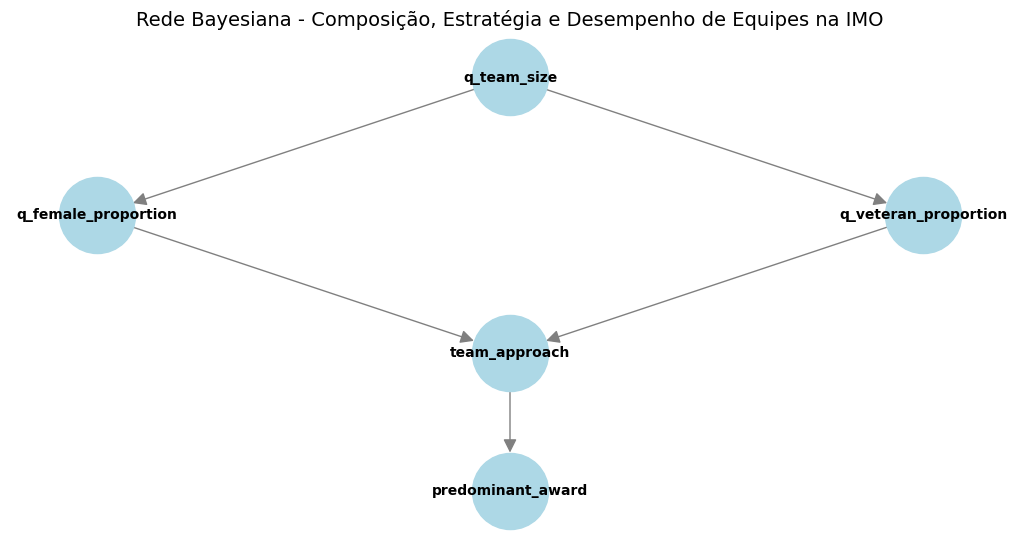

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

model = DiscreteBayesianNetwork(
    [
        ("q_team_size", "q_female_proportion"),
        ("q_team_size", "q_veteran_proportion"),
        ("q_female_proportion", "team_approach"),
        ("q_veteran_proportion", "team_approach"),
        ("team_approach", "predominant_award"),
    ]
)

G = nx.DiGraph()
G.add_nodes_from(model.nodes())
G.add_edges_from(model.edges())

pos = {
    "q_team_size": (0,3),
    "q_female_proportion": (-2, 2),
    "q_veteran_proportion": (2, 2),
    "team_approach": (0, 1),
    "predominant_award": (0, 0)
}

plt.figure(figsize=(10,5))
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue',
        font_size=10, font_weight='bold', arrowsize=20, edge_color='gray')
plt.title("Rede Bayesiana - Composição, Estratégia e Desempenho de Equipes na IMO", fontsize=14)
plt.axis('off')
plt.show()

# 4. Ajuste da Rede

In [ ]:
import pandas as pd
import numpy as np
import warnings
import itertools
from pgmpy.estimators import BayesianEstimator

warnings.filterwarnings('ignore', category=FutureWarning)

# 1. Configurar o Pandas para não cortar nada
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# 2. Calcular o estimador normalmente
estimador = BayesianEstimator(model, data)
cpd = estimador.estimate_cpd('team_approach', prior_type='BDeu', equivalent_sample_size=10)

# 3. Extrair os dados para construir um Pandas DataFrame real
variavel_alvo = cpd.variables[0]
evidencias = cpd.variables[1:]

# Obter matriz de valores e nomes dos estados
valores = cpd.get_values()
linhas = cpd.state_names[variavel_alvo]

# Construir os nomes das colunas com base nas combinações das variáveis de evidência
if evidencias:
    estados_evidencias = [cpd.state_names[ev] for ev in evidencias]
    combinacoes = list(itertools.product(*estados_evidencias))
    colunas = pd.MultiIndex.from_tuples(combinacoes, names=evidencias)
    df_cpd = pd.DataFrame(valores, index=linhas, columns=colunas)
else:
    df_cpd = pd.DataFrame(valores, index=linhas, columns=["Probabilidade"])

print("Tabela CPD Completa (team_approach):\n")
display(df_cpd)

Tabela CPD Completa (team_approach):



q_female_proportion             Alta Proporcao                          \
q_veteran_proportion            Alta Proporcao Ausente Baixa Proporcao   
Ausente                               0.000596     0.2        0.001721   
Fáceis+Médias+Esforçar Difíceis       0.057841     0.2        0.029260   
Fáceis+Pontuar Bem Médias             0.038760     0.2        0.056799   
Garantir Fáceis                       0.239117     0.2        0.166954   
Não Garantir Fáceis                   0.663685     0.2        0.745267   

q_female_proportion                              Ausente            \
q_veteran_proportion                  Sem Alta Proporcao   Ausente   
Ausente                          0.023192       0.012834  0.809524   
Fáceis+Médias+Esforçar Difíceis  0.012278       0.160931  0.047619   
Fáceis+Pontuar Bem Médias        0.001364       0.098240  0.047619   
Garantir Fáceis                  0.055935       0.235434  0.047619   
Não Garantir Fáceis              0.907231       0.492561  0.047619   

q_female_proportion                                       Baixa Proporcao  \
q_veteran_proportion            Baixa Proporcao       Sem  Alta Proporcao   
Ausente                                0.054376  0.071971        0.003770   
Fáceis+Médias+Esforçar Difíceis        0.136523  0.103242        0.064094   
Fáceis+Pontuar Bem Médias              0.058110  0.044378        0.113772   
Garantir Fáceis                        0.117853  0.083008        0.324906   
Não Garantir Fáceis                    0.633139  0.697402        0.493458   

q_female_proportion                                                \
q_veteran_proportion            Ausente Baixa Proporcao       Sem   
Ausente                             0.2        0.036798  0.089696   
Fáceis+Médias+Esforçar Difíceis     0.2        0.119432  0.107487   
Fáceis+Pontuar Bem Médias           0.2        0.052292  0.018532   
Garantir Fáceis                     0.2        0.150420  0.077835   
Não Garantir Fáceis                 0.2        0.641059  0.706449   

q_female_proportion                        Sem                          \
q_veteran_proportion            Alta Proporcao Ausente Baixa Proporcao   
Ausente                               0.000552     0.2        0.002933   
Fáceis+Médias+Esforçar Difíceis       0.177055     0.2        0.190616   
Fáceis+Pontuar Bem Médias             0.265306     0.2        0.190616   
Garantir Fáceis                       0.300607     0.2        0.167155   
Não Garantir Fáceis                   0.256481     0.2        0.448680   

q_female_proportion                        
q_veteran_proportion                  Sem  
Ausente                          0.003413  
Fáceis+Médias+Esforçar Difíceis  0.112628  
Fáceis+Pontuar Bem Médias        0.112628  
Garantir Fáceis                  0.139932  
Não Garantir Fáceis              0.631399

1- Cenário sem veteranos e sem mulheres:

    A tabela de distribuição condicional demonstra que equipes formadas exclusivamente por calouros (sem veteranos e sem representação feminina) possuem uma enorme probabilidade (63%) de não conseguir garantir pontos nem nas questões mais fáceis da IMO.

2- Cenário com alta proporção veteranos e com baixa proporção de mulheres:

    Quando isolamos o efeito da experiência, observamos que a alta proporção de veteranos desloca a massa de probabilidade das categorias inferiores para as superiores. A chance de a equipe garantir as fáceis salta de 7% para 32%.

3- Cenário com melhor desempenho:

    A rede bayesiana indica que a maior probabilidade de atingir a maturidade máxima de prova ('Fáceis+Médias+Esforçar Difíceis') ocorre sob a composição de baixa proporção de veteranos e sem mulheres, com 19% de chance.

# 5. Inferência

In [ ]:
infer = VariableElimination(model)
posterior_p1 = infer.query(['team_approach'], 
                           evidence={'q_female_proportion': 'Sem', ''})

print(posterior_p1)

In [ ]:
display(data[['q_team_size', 'q_female_proportion', 'q_veteran_proportion', 'team_approach', 'predominant_award']].head(10))
posterior_p2 = infer.query(
    ['team_approach'], 
    evidence = {
        'q_team_size': 'Completa', 
        'q_female_proportion': 'Alta Proporcao', 
        'q_veteran_proportion': 'Sem', 
        'predominant_award': 'Ouro'
    }
)
print(posterior_p2)